# Added Signals and Linear Models

To recap 
1. The first notebook established how the returns are setup and the proper normalize (their volatility cross-sectionally) for each contract
2. The second notebook examine the returns of long-only for the backtest and then tried a generic momentum signal, although the momentum signal worked in-sample it failed greatly out-of-sample.

What this notebook will do is that it will add more price-action/time series signals into our model, and rather than using the factor as the signal to trade it will be fitted into a model. The overall goal is to setup a model ready for the atlernative and machine learning while *enhancing* it with all of the data that is currently available. This notebook will specifically cover
1. The use of Logistic and OLS models to test and predict returns
2. The basis for how those models will be analyzed and the performance they generate, how to measure their in-sample vs. out-of-sample loss
3. How they perform when features are added and a framework for adding features

All of these are necessary features for moving towards alternative sentiment data and machine learning models

# Packages

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Paths and Global Variables

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")
zone_path = os.path.join(data_path, "ZoneImputedFirstRateData")

In [76]:
day_renamer = {
    "day_after"   : "Day After",
    "day_before"  : "Day Before",
    "post_meeting": "Post Meeting",
    "pre_meeting" : "Pre Meeting"}

zone_renamer = {
    "zone1": "Day Before",
    "zone2": "Before Meeting",
    "zone3": "After Meeting",
    "zone4": "Day After"}

sample_renamer = {
    "lday_vol" : "Prior Day",
    "lzone_vol": "Prior Event"}

vol_renamer = {
    "lday"       : "Prior Day",
    "lzone"      : "Prior Event",
    "combined"   : "Prior Day and Event",
    "raw_rtn"    : "Raw Return",
    "impute_open": "Raw Return"}

param_renamer = {
    "const"    : "Const",
    "lday_vol" : "Prior Day Vol",
    "lzone_vol": "Prio Event Vol"}

tmp_renamer = {
    "name"    : "Trading Zone",
    "vol_type": "Vol Estimator",
    "ticker"  : "Contract"}

sample_renamer_ = {
    "in_sample" : "In-Sample",
    "out_sample": "Out-Sample",
    "train_test": "Train-Test"}

param_renamer_ = {
    "coeff" : "Coeff", 
    "pvalue": r"$p$-value",
    "tvalue": r"$t$-value"}

scheme_renamer_ = {
    "logit"  : "Logistic",
    "ols"    : "OLS", 
    "avg_rtn": "Avg"}

replacer = {**day_renamer, **zone_renamer, **sample_renamer, **param_renamer, **vol_renamer, **tmp_renamer, **sample_renamer_, **param_renamer_, **scheme_renamer_}

In [4]:
import sys; sys.path.append(os.path.join(repo_path, "src"))
from SignalGenerator import SignalGenerator

sg = SignalGenerator()

# Fitting the Historical Performance In-Sample/Full-Sample

Before we begin adding more signals to the model lets first start by fitting the signals to the return. We'll use cumulative volatility normalized returns over the trading period as the endogenous target, this can be changed in the future but for now to make it easier we'll use this. The feature that we pass through to the model will be the average prior event return of the volatility normalized returns

In [5]:
logit_is = sg.apply_model(spec_name = "logit__cum_rtn__lag_mean_rtn", scheme = "in_sample")
ols_is   = sg.apply_model(spec_name = "ols__cum_rtn__lag_mean_rtn", scheme = "in_sample")

df_is = (pd
    .concat([
        logit_is.assign(model = "logit"),
        ols_is.assign(model = "ols")])
    .loc[lambda x: x.vol_type == "combined"])

The first part we want to examine is how similar are the trading signals between the OLS and Logistic. 

In [6]:
df_signals = (df_is
    [["model", "meeting_id", "zone", "name", "signal", "ticker"]]
    .drop_duplicates())

df_matched = (df_signals
    .pivot(index = ["meeting_id", "zone", "name", "ticker"], columns = "model", values = "signal")
    .apply(lambda x: np.where(x > 0, 1, 0))
    .assign(match = lambda x: np.where(x.ols == x.logit, "matched", "not matched"))
    .reset_index()
    .drop(columns = ["logit", "ols"])
    .groupby(["zone", "name", "ticker", "match"])
    .agg("count")
    .reset_index()
    .pivot(index = ["ticker", "name", "zone"], columns = "match", values = "meeting_id")
    .assign(cuml_val = lambda x: x.sum(axis = 1))
    .reset_index()
    .melt(id_vars = ["ticker", "name", "zone", "cuml_val"])
    .assign(prop = lambda x: x.value / x.cuml_val)
    .loc[lambda x: x.match == "matched"])

In [7]:
df_signal_corr = (df_signals
    .pivot(index = ["meeting_id", "zone", "name", "ticker"], columns = "model", values = "signal")
    .reset_index()
    .drop(columns = ["meeting_id"])
    .groupby(["zone", "name", "ticker"])
    .agg("corr")
    .loc[lambda x: x.ols != 1]
    .reset_index())

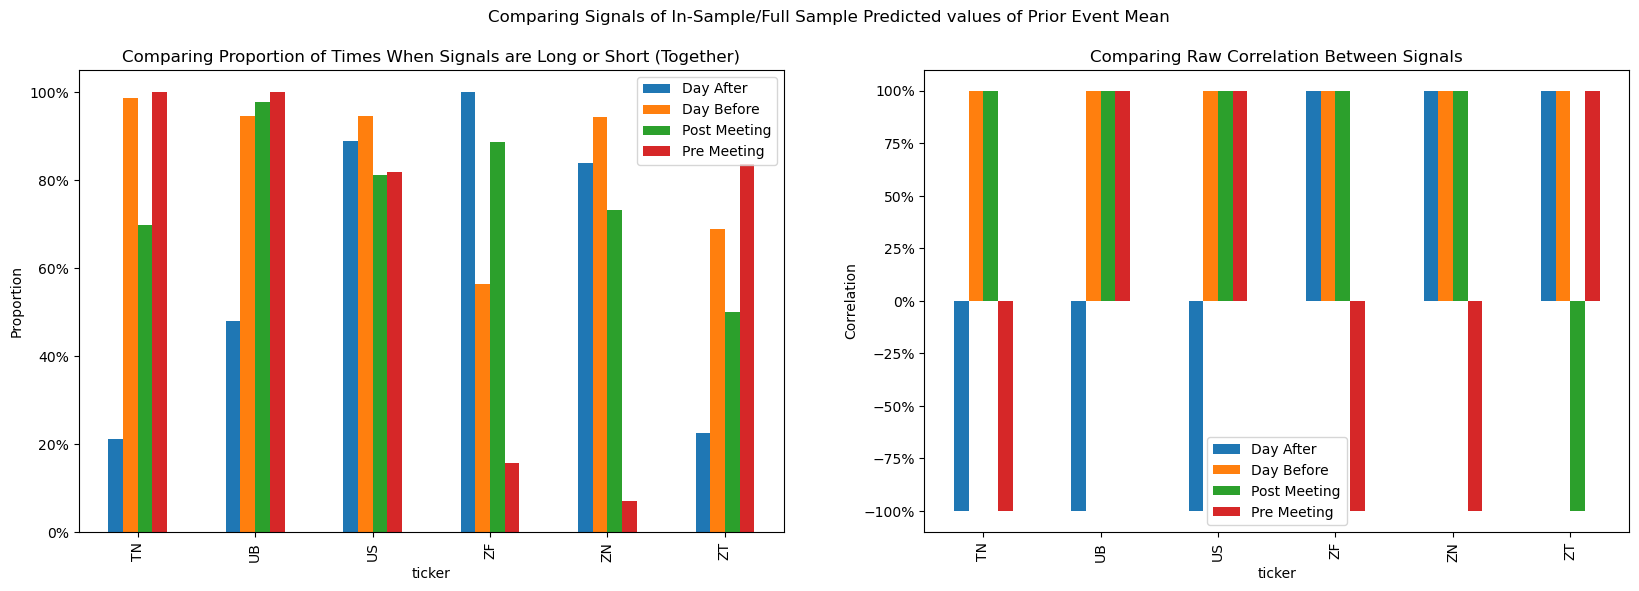

In [8]:
fig, axes = plt.subplots(ncols = 2, figsize = (20,6))

(df_matched
    .rename(columns = {"name": ""})
    .pivot(index = "ticker", columns = "", values = "prop")
    .rename(columns = replacer)
    .plot(
        ylabel = "Proportion",
        kind   = "bar", 
        ax     = axes[0],
        title  = "Comparing Proportion of Times When Signals are Long or Short (Together)"))

(df_signal_corr
    .rename(columns = {"name": ""})
    .pivot(index = "ticker", columns = "", values = "ols")
    .rename(columns = replacer)
    .plot(
        kind   = "bar", 
        ax     = axes[1],
        ylabel = "Correlation",
        title  = "Comparing Raw Correlation Between Signals"))

fig.suptitle("Comparing Signals of In-Sample/Full Sample Predicted values of Prior Event Mean")
for ax in axes.flatten(): ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

Now examine the parameters of the model. We are primarily interested in the OLS results since they are more testable

In [9]:
names = ["logit__cum_rtn__lag_mean_rtn", "ols__cum_rtn__lag_mean_rtn"]
paths = [
    os.path.join(data_path, "Models", model, "Params.parquet")
    for model in names]

df_params = pd.read_parquet(path = paths, engine = "pyarrow")

In [10]:
df_is_params = (df_params
    .loc[lambda x: x.vol_type == "combined"]
    .loc[lambda x: x.param    == "lag_mean_rtn"]
    .loc[lambda x: x.scheme   == "in_sample"])

Most of the coefficients are quite weak within the in-sample/full-sample framework

In [11]:
(df_is_params
    .loc[lambda x: x.spec_name == "ols__cum_rtn__lag_mean_rtn"]
    [["ticker", "name", "coeff", "pvalue", "tvalue"]]
    .melt(id_vars = ["ticker", "name"])
    .replace(replacer)
    .rename(columns = {"variable": ""})
    .pivot(index = ["ticker", "name"], columns = "", values = "value")
    .rename(columns = replacer))

$p$-value  $t$-value     Coeff
ticker name                                        
TN     Day After      0.468567  -0.728565 -0.000935
       Day Before     0.211910   1.259068  0.001381
       Post Meeting   0.215706  -1.248713 -0.000607
       Pre Meeting    0.859831  -0.177198 -0.000133
UB     Day After      0.373788  -0.892650 -0.000790
       Day Before     0.107937   1.619333  0.001253
       Post Meeting   0.167867  -1.387275 -0.000515
       Pre Meeting    0.994806  -0.006523 -0.000004
US     Day After      0.914232  -0.107894 -0.000081
       Day Before     0.246108   1.164664  0.000837
       Post Meeting   0.241432  -1.176363 -0.000427
       Pre Meeting    0.312341   1.013955  0.000533
ZF     Day After      0.937174  -0.078965 -0.000062
       Day Before     0.465332   0.732128  0.000546
       Post Meeting   0.445613  -0.764957 -0.000324
       Pre Meeting    0.633992   0.477167  0.000277
ZN     Day After      0.333801  -0.969836 -0.000703
       Day Before     0.129741   1.524095  0.001033
       Post Meeting   0.426847  -0.796937 -0.000312
       Pre Meeting    0.279376   1.085960  0.000584
ZT     Day After      0.496694  -0.681479 -0.000389
       Day Before     0.518965   0.646587  0.000413
       Post Meeting   0.958204   0.052502  0.000021
       Pre Meeting    0.085530   1.731790  0.000678

Now plot the playback of the returns which is just using the predicted OLS and Logistic models. 

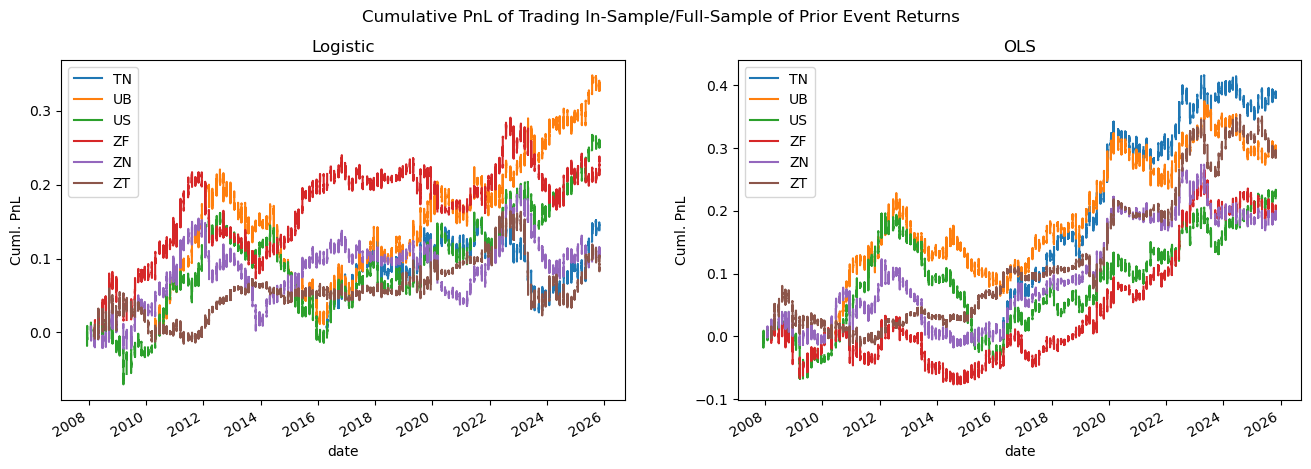

In [12]:
is_models = {
    "Logistic": logit_is,
    "OLS"     : ols_is}

fig, axes = plt.subplots(ncols = len(is_models.keys()), figsize = (16,5))
for key, ax in zip(is_models.keys(), axes.flatten()):
    
    (is_models
        [key]
        .loc[lambda x: x.vol_type == "combined"]
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "signal_rtn")
        .cumsum()
        .plot(
            ax     = ax,
            ylabel = "Cuml. PnL",
            title  = key))

fig.suptitle("Cumulative PnL of Trading In-Sample/Full-Sample of Prior Event Returns")
plt.show()

In [13]:
df_is = (pd
    .concat([is_models[key].assign(model = key) for key in is_models.keys()])
    .loc[lambda x: x.vol_type == "combined"])

In [14]:
(df_is
    [["zone", "name", "ticker", "signal_rtn", "model"]]
    .groupby(["zone", "name", "ticker", "model"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .reset_index()
    .drop(columns = ["zone"])
    .rename(columns = {
        "ticker": "",
        "model" : "Model",
        "name"  : "Name"})
    .replace(replacer)
    .pivot(index = ["Name"], columns = ["", "Model"], values = "signal_rtn"))

TN                  UB                  US            \
Model         Logistic       OLS  Logistic       OLS  Logistic       OLS   
Name                                                                       
Day After    -0.303349  0.598852  0.084858 -0.014413  0.141352  0.135595   
Day Before    0.223185  0.223185  0.371602  0.402521  0.077030  0.238416   
Post Meeting  0.962666  1.257838  0.650285  0.552799  1.002046  0.053621   
Pre Meeting   0.680552  0.680552  0.323219  0.323219  0.201231  0.136338   

                    ZF                  ZN                  ZT            
Model         Logistic       OLS  Logistic       OLS  Logistic       OLS  
Name                                                                      
Day After     0.175141  0.175141  0.159200  0.134623 -0.057224  0.197883  
Day Before    0.282549 -0.013199  0.167112  0.094501  0.150701  0.078979  
Post Meeting  0.376969  0.878263  0.057112  0.727873 -0.292647  0.306912  
Pre Meeting  -0.043875  0.159276 -0.170120  0.082206  0.230939  0.452613

In [15]:
df_tvalue = (df_is_params
    [["name", "ticker", "tvalue", "spec_name"]]
    .assign(spec_name = lambda x: x.spec_name.str.split("_").str[0])
    .replace({"logit": "Logistic", "ols": "OLS"})
    .rename(columns = {"spec_name": "model"}))

In [16]:
df_sharpe = (df_is
    [["zone", "name", "ticker", "signal_rtn", "model"]]
    .groupby(["zone", "name", "ticker", "model"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .reset_index())

In [17]:
df_tvalue.head(5)

,name,ticker,tvalue,model
1,day_before,TN,1.174152,Logistic
7,pre_meeting,TN,0.060755,Logistic
13,post_meeting,TN,-2.441247,Logistic
19,day_after,TN,1.067651,Logistic
25,day_before,UB,1.675006,Logistic


In [18]:
(df_sharpe.head(5))

,zone,name,ticker,model,signal_rtn
0,zone1,day_before,TN,Logistic,0.223185
1,zone1,day_before,TN,OLS,0.223185
2,zone1,day_before,UB,Logistic,0.371602
3,zone1,day_before,UB,OLS,0.402521
4,zone1,day_before,US,Logistic,0.077030


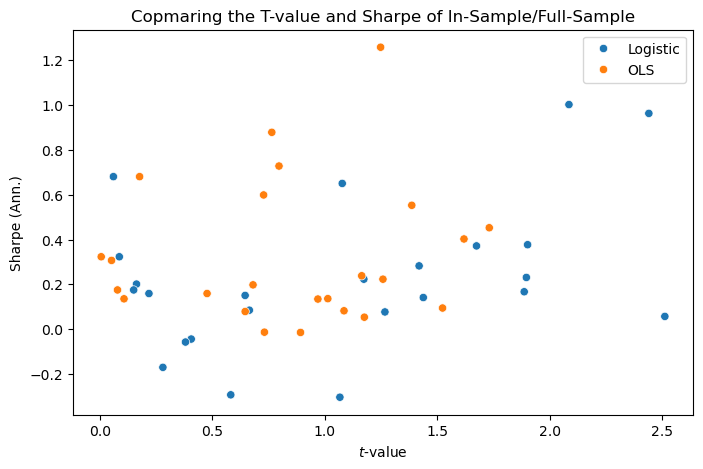

In [19]:
df_combined = (df_tvalue
    .merge(right = df_sharpe, how = "inner", on = ["name", "ticker", "model"])
    .assign(tvalue = lambda x: x.tvalue.abs()))

fig, axes = plt.subplots(figsize = (8,5))

sns.scatterplot(
    data = df_combined.rename(columns = {"model": ""}),
    x    = "tvalue",
    y    = "signal_rtn",
    hue  = "",
    ax   = axes)

axes.set_xlabel(r"$t$-value")
axes.set_ylabel("Sharpe (Ann.)")
axes.set_title("Copmaring the T-value and Sharpe of In-Sample/Full-Sample")
plt.show()

In [20]:
df_is_rtn = (df_is
    [["date", "model", "signal_rtn"]]
    .groupby(["date", "model"])
    .agg("mean")
    .reset_index()
    .rename(columns = {"model": ""})
    .pivot(index = "date", columns = "", values = "signal_rtn")
    .assign(Avg = lambda x: x.mean(axis = 1)))

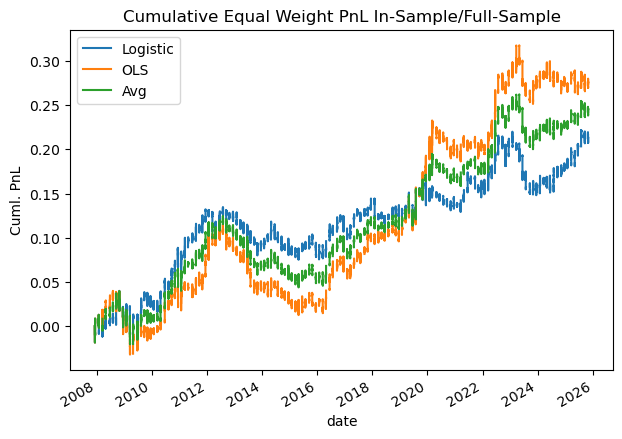

In [21]:
(df_is_rtn
    .cumsum()
    .plot(
        figsize = (7,5),
        ylabel  = "Cuml. PnL",
        title   = "Cumulative Equal Weight PnL In-Sample/Full-Sample"))

plt.show()

Below is the sharpe of an equal weight portfolio of each signal

In [22]:
(df_is_rtn
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .to_frame(name = "Sharpe")
    .T)

,Logistic,OLS,Avg
Sharpe,0.246808,0.302068,0.308093


Below is the sharpe per each event controlling for each model 

In [23]:
(df_is
    [["date", "name", "model", "signal_rtn"]]
    .groupby(["date", "name", "model"])
    .agg("mean")
    .reset_index()
    .drop(columns = ["date"])
    .groupby(["name", "model"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .reset_index()
    .replace(replacer)
    .rename(columns = {
        "model": "Model",
        "name" : "Name"})
    .pivot(index = "Name", columns = "Model", values = "signal_rtn"))

Model,Logistic,OLS
Name,,
Day After,0.139483,0.316549
Day Before,0.263250,0.205226
Post Meeting,0.468360,0.655830
Pre Meeting,0.391282,0.315531


# Comparing In-Sample, Train/Test, and Expanding Out-of-Sample Models

In [27]:
models  = ["logit", "ols"]
schemes = ["in_sample", "train_test", "out_sample"]
inputs  = [("{}__cum_rtn__lag_mean_rtn".format(model), scheme) for model in models for scheme in schemes]

In [30]:
df_signal_rtn = (pd
    .concat([sg.apply_model(spec_name = input_[0], scheme = input_[1]) for input_ in inputs]))

In [40]:
df_scheme_rtn = (df_signal_rtn
    [["date", "scheme", "signal_rtn", "spec_name"]]
    .groupby(["date", "scheme", "spec_name"])
    .agg("mean")
    .reset_index())

In [63]:
df_scheme_tmp = (df_scheme_rtn
    .assign(spec_name = lambda x: x.spec_name.str.split("_").str[0])
    .rename(columns = {"spec_name": ""})
    .pivot(index = ["date", "scheme"], columns = "", values = "signal_rtn")
    .assign(avg_rtn = lambda x: x.mean(axis = 1))
    .reset_index())

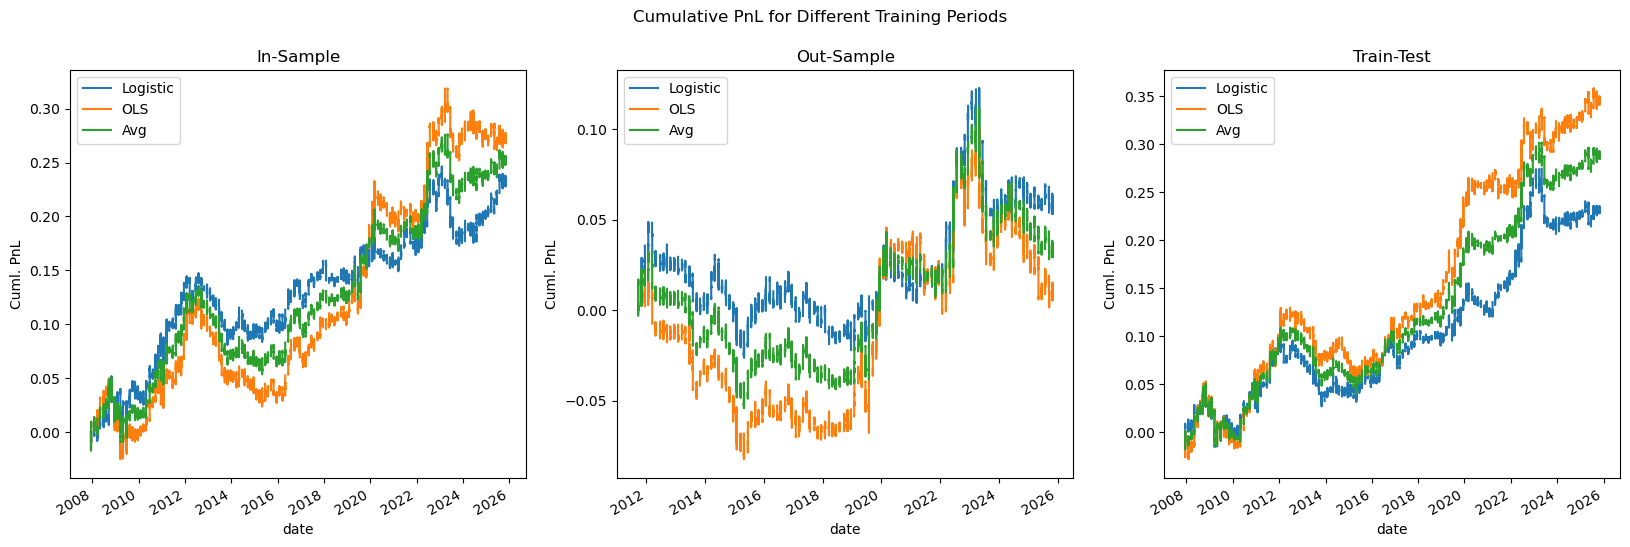

In [78]:
schemes = (df_scheme_tmp
    .scheme
    .drop_duplicates()
    .sort_values()
    .to_list())

fig, axes = plt.subplots(ncols = len(schemes), figsize = (20,6))

for scheme, ax in zip(schemes, axes.flatten()): 

    (df_scheme_tmp
        .loc[lambda x: x.scheme == scheme]
        .drop(columns = ["scheme"])
        .set_index("date")
        .cumsum()
        .rename(columns = replacer)
        .plot(
            ax     = ax,
            title  = replacer[scheme],
            ylabel = "Cuml. PnL"))

fig.suptitle("Cumulative PnL for Different Training Periods")
plt.show()

In [87]:
(df_scheme_tmp
    .melt(id_vars = ["date", "scheme"])
    .dropna()
    .drop(columns = ["date"])
    .groupby(["scheme", ""])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(390 * 8))
    .reset_index()
    .replace(replacer)
    .rename(columns = {"scheme": "Train Set"})
    .pivot(index = "Train Set", columns = "", values = "value"))

,Avg,Logistic,OLS
Train Set,,,
In-Sample,0.319946,0.276531,0.306527
Out-Sample,0.053783,0.090465,0.013961
Train-Test,0.394825,0.288795,0.381744


# More Price, Return, and Volume Signals

While still using the same data we can add in more models

In [132]:
path = r"A:\GitHub\FOMCDrift\data\VolatilityNormalizedReturns\InSample.parquet"
(pd
    .read_parquet(path = path)
    .loc[lambda x: x.vol_type == "combined"]
    [["split", "ticker", "zone", "vol_type", "meeting_id", "impute_open"]]
    .loc[lambda x: x.impute_open != 0]
    .groupby(["split", "ticker", "zone", "vol_type", "meeting_id"])
    ["impute_open"]
    .agg(["median"])
    .add_suffix("_val")
    .reset_index()
    .loc[lambda x: x.zone == x.zone.min()])

,split,ticker,zone,vol_type,meeting_id,median_val
0,full,TN,zone1,combined,159,-0.015625
1,full,TN,zone1,combined,160,-0.015625
2,full,TN,zone1,combined,161,-0.015625
3,full,TN,zone1,combined,162,-0.015625
4,full,TN,zone1,combined,163,0.015625
...,...,...,...,...,...,...
2664,full,ZT,zone1,combined,233,0.003906
2665,full,ZT,zone1,combined,234,-0.003906
2666,full,ZT,zone1,combined,235,0.003906
2667,full,ZT,zone1,combined,236,0.003906


In [104]:
path = r"A:\GitHub\FOMCDrift\data\Signals\HistoricalEventMean.parquet"
(pd.read_parquet(path = path, engine = "pyarrow"))

,signal_name,scheme,split,ticker,zone,name,vol_type,meeting_id,signal,n_events,last_meeting_id
0,HistoricalEventMean,in_sample,full,TN,zone1,day_before,combined,159,-0.000001,78,237
1,HistoricalEventMean,in_sample,full,TN,zone1,day_before,combined,160,-0.000001,78,237
2,HistoricalEventMean,in_sample,full,TN,zone1,day_before,combined,161,-0.000001,78,237
3,HistoricalEventMean,in_sample,full,TN,zone1,day_before,combined,162,-0.000001,78,237
4,HistoricalEventMean,in_sample,full,TN,zone1,day_before,combined,163,-0.000001,78,237
...,...,...,...,...,...,...,...,...,...,...,...
25707,HistoricalEventMean,out_sample,oos,ZT,zone4,day_after,lzone,233,0.000001,138,232
25708,HistoricalEventMean,out_sample,oos,ZT,zone4,day_after,lzone,234,0.000001,139,233
25709,HistoricalEventMean,out_sample,oos,ZT,zone4,day_after,lzone,235,0.000001,140,234
25710,HistoricalEventMean,out_sample,oos,ZT,zone4,day_after,lzone,236,0.000001,141,235
